Launch velocity v0 = (30.40, 9.40, 6.90) m/s


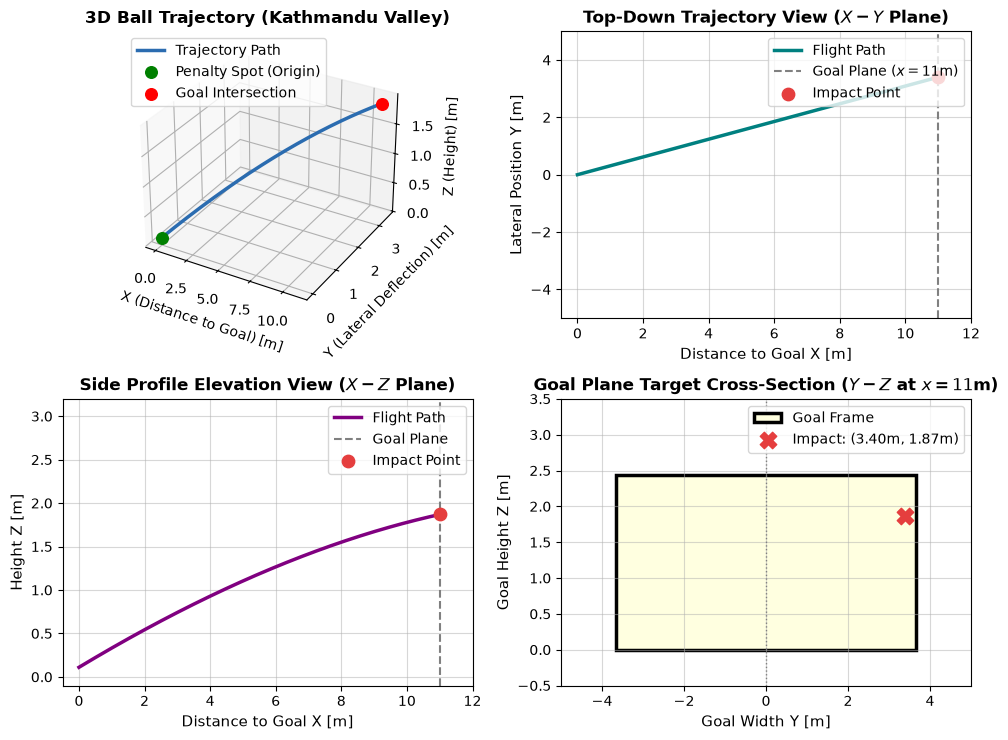

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
from scipy.integrate import solve_ivp

# --- 1. Geometry & Initial Conditions ---
GOAL_X = 11.0
Y_MIN, Y_MAX = -3.66, 3.66
Z_MIN, Z_MAX = 0.0, 2.44
G = 9.81

# Tracking coordinates
p0 = np.array([0.00, 0.00, 0.11])  # t = 0.00 s
p1 = np.array([1.50, 0.45, 0.44])  # t = 0.05 s
p2 = np.array([2.96, 0.86, 0.74])  # t = 0.10 s
dt = 0.05

# --- 2. Parameter Estimation & ODE Solution ---
vx1 = (p1[0] - p0[0]) / dt
vx2 = (p2[0] - p1[0]) / dt

L1 = np.linalg.norm(p1 - p0)
L2 = np.linalg.norm(p2 - p1)
ds = (L1 + L2) / 2.0

# Drag parameter q (m^-1)
q = np.log(vx1 / vx2) / ds

# Initial velocity at t=0s from the three-point finite difference
v0 = (4 * p1 - p2 - 3 * p0) / (2 * dt)
print(f"Launch velocity v0 = ({v0[0]:.2f}, {v0[1]:.2f}, {v0[2]:.2f}) m/s")


def trajectory_ode(t, state, q, g):
    x, y, z, vx, vy, vz = state
    V = np.sqrt(vx**2 + vy**2 + vz**2)
    return [vx, vy, vz, -q * V * vx, -q * V * vy, -g - q * V * vz]


def goal_plane_event(t, state, q, g):
    return state[0] - GOAL_X


goal_plane_event.terminal = True
goal_plane_event.direction = 1

init_state = np.concatenate((p0, v0))
sol = solve_ivp(
    trajectory_ode,
    (0, 1.0),
    init_state,
    args=(q, G),
    events=goal_plane_event,
    max_step=0.001,
)

x_vals, y_vals, z_vals = sol.y[0], sol.y[1], sol.y[2]
y_g, z_g = y_vals[-1], z_vals[-1]

# --- 3. Visualization Setup (2x2 Grid matching reference styles) ---
fig = plt.figure(figsize=(10, 7.5))

# --- Graph 1: 3D Ball Trajectory ---
ax1 = fig.add_subplot(221, projection="3d")
ax1.plot(
    x_vals, y_vals, z_vals, color="#2B6CB0", linewidth=2.5, label="Trajectory Path"
)
ax1.scatter(
    [p0[0]], [p0[1]], [p0[2]], color="green", s=70, label="Penalty Spot (Origin)"
)
ax1.scatter(
    [GOAL_X], [y_g], [z_g], color="red", s=70, label="Goal Intersection"
)
ax1.set_xlabel("X (Distance to Goal) [m]")
ax1.set_ylabel("Y (Lateral Deflection) [m]")
ax1.set_zlabel("Z (Height) [m]")
ax1.set_title("3D Ball Trajectory (Kathmandu Valley)", fontweight="bold")
ax1.legend(loc="upper left")

# --- Graph 2: Top-Down Trajectory View (X-Y Plane) ---
ax2 = fig.add_subplot(222)
ax2.plot(
    x_vals, y_vals, color="#008080", linewidth=2.5, label="Flight Path"
)
ax2.axvline(
    GOAL_X,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Goal Plane ($x = {int(GOAL_X)}$m)",
)
ax2.scatter(
    GOAL_X, y_g, color="#E53E3E", s=80, zorder=5, label="Impact Point"
)
ax2.set_xlim(-0.5, 12.0)
ax2.set_ylim(-5.0, 5.0)
ax2.set_xlabel("Distance to Goal X [m]", fontsize=11)
ax2.set_ylabel("Lateral Position Y [m]", fontsize=11)
ax2.set_title("Top-Down Trajectory View ($X-Y$ Plane)", fontweight="bold")
ax2.grid(True, linestyle="-", alpha=0.5)
ax2.legend(loc="upper right")

# --- Graph 3: Side Profile Elevation View (X-Z Plane) ---
ax3 = fig.add_subplot(223)
ax3.plot(
    x_vals, z_vals, color="#800080", linewidth=2.5, label="Flight Path"
)
ax3.axvline(
    GOAL_X, color="gray", linestyle="--", linewidth=1.5, label="Goal Plane"
)
ax3.scatter(
    GOAL_X, z_g, color="#E53E3E", s=80, zorder=5, label="Impact Point"
)
ax3.set_xlim(-0.5, 12.0)
ax3.set_ylim(-0.1, 3.2)
ax3.set_xlabel("Distance to Goal X [m]", fontsize=11)
ax3.set_ylabel("Height Z [m]", fontsize=11)
ax3.set_title("Side Profile Elevation View ($X-Z$ Plane)", fontweight="bold")
ax3.grid(True, linestyle="-", alpha=0.5)
ax3.legend(loc="upper right")

# --- Graph 4: Goal Plane Target Cross-Section (Y-Z at x = 11m) ---
ax4 = fig.add_subplot(224)
goal_bg = Rectangle(
    (Y_MIN, Z_MIN),
    Y_MAX - Y_MIN,
    Z_MAX - Z_MIN,
    linewidth=2.5,
    edgecolor="black",
    facecolor="#FFFFE0",
    label="Goal Frame",
    zorder=1,
)
ax4.add_patch(goal_bg)
ax4.axvline(0, color="gray", linestyle=":", linewidth=1.0, zorder=2)
ax4.scatter(
    y_g,
    z_g,
    color="#E53E3E",
    marker="X",
    s=140,
    zorder=4,
    label=f"Impact: ({y_g:.2f}m, {z_g:.2f}m)",
)
ax4.set_xlim(-5.0, 5.0)
ax4.set_ylim(-0.5, 3.5)
ax4.set_xlabel("Goal Width Y [m]", fontsize=11)
ax4.set_ylabel("Goal Height Z [m]", fontsize=11)
ax4.set_title(
    f"Goal Plane Target Cross-Section ($Y-Z$ at $x = {int(GOAL_X)}$m)",
    fontweight="bold",
)
ax4.grid(True, linestyle="-", alpha=0.5)
ax4.legend(loc="upper right")

plt.tight_layout()
plt.show()